# Unpenalized elbow fits for $p=1,2,3$: 50 processes per order

This first methodological comparison retains exactly two selectors and gives neither an order nor a dimension penalty. Both are fitted directly to the empirical minimum-width curve.

1. **Classical two-affine-line L-method.** For every admissible boundary, fit one affine line to each of two disjoint segments, require at least two points per segment, and minimize the segment-size-weighted RMSE. If the boundary is between $k=p$ and $k=p+1$, the selected order is $\widehat p=p$.

2. **Modified affine-plus-constant L-method.** For every candidate plateau onset $q$, fit an affine head through $k\le q$ and a constant tail through $k\ge q$. The shared point $q$ makes $q=2$ admissible, so this method can select AR(1). It uses the same segment-size-weighted RMSE principle.

The experiment below uses the same simulated curves for both fits: 50 processes for each true order, $T=2{,}000$, and embedding dimensions $k=1,\ldots,10$. The optimizer schedule comparison is maintained separately in [the tuning notebook](ar_projected_subgradient_eta0_beta_tuning.ipynb).


In [1]:
import sys                                                                                          ### INFRASTRUCTURE
from pathlib import Path                                                                            ### INFRASTRUCTURE

import matplotlib.pyplot as plt                                                                     ### PLOTTING
import numpy as np
import pandas as pd

AR_CODE_DIR = next((                                                                                ### INFRASTRUCTURE
    candidate.resolve()                                                                             ### INFRASTRUCTURE
    for root in (Path.cwd(), *Path.cwd().parents)                                                   ### INFRASTRUCTURE
    for candidate in (root / "Code" / "Code_AR_processes", root)                                    ### INFRASTRUCTURE
    if (candidate / "ar_tools/functions.py").is_file()                                              ### INFRASTRUCTURE
    and (candidate / "ar_tools/L_method.py").is_file()                                              ### INFRASTRUCTURE
), None)                                                                                            ### INFRASTRUCTURE
if AR_CODE_DIR is None:                                                                             ### INFRASTRUCTURE
    raise FileNotFoundError("Could not locate Code/Code_AR_processes.")                             ### INFRASTRUCTURE
PROJECT_ROOT = AR_CODE_DIR.parents[1]                                                               ### INFRASTRUCTURE
if str(PROJECT_ROOT) not in sys.path:                                                               ### INFRASTRUCTURE
    sys.path.insert(0, str(PROJECT_ROOT))                                                           ### INFRASTRUCTURE

from Code.Code_AR_processes.ar_tools.descent import batched_geometric_width_curves
from Code.Code_AR_processes.ar_tools.L_method import l_method_selector
from Code.Code_AR_processes.ar_tools.functions import (
    jones_ar_coefficients,
    simulate_uniform_ar,
)

ORDER_SELECTION_IMAGES_DIR = (                                                                      ### INFRASTRUCTURE
    AR_CODE_DIR / "outputs" / "images" / "order_selection"                                          ### INFRASTRUCTURE
)                                                                                                   ### INFRASTRUCTURE
(ORDER_SELECTION_IMAGES_DIR / "cross_process").mkdir(                                               ### INFRASTRUCTURE
    parents=True, exist_ok=True                                                                     ### INFRASTRUCTURE
)                                                                                                   ### INFRASTRUCTURE
plt.style.use("seaborn-v0_8-whitegrid")                                                             ### PLOTTING


Completed 10/50 AR(1) processes
Completed 20/50 AR(1) processes
Completed 30/50 AR(1) processes
Completed 40/50 AR(1) processes
Completed 50/50 AR(1) processes
Completed 10/50 AR(2) processes
Completed 20/50 AR(2) processes
Completed 30/50 AR(2) processes
Completed 40/50 AR(2) processes
Completed 50/50 AR(2) processes
Completed 10/50 AR(3) processes
Completed 20/50 AR(3) processes
Completed 30/50 AR(3) processes
Completed 40/50 AR(3) processes
Completed 50/50 AR(3) processes


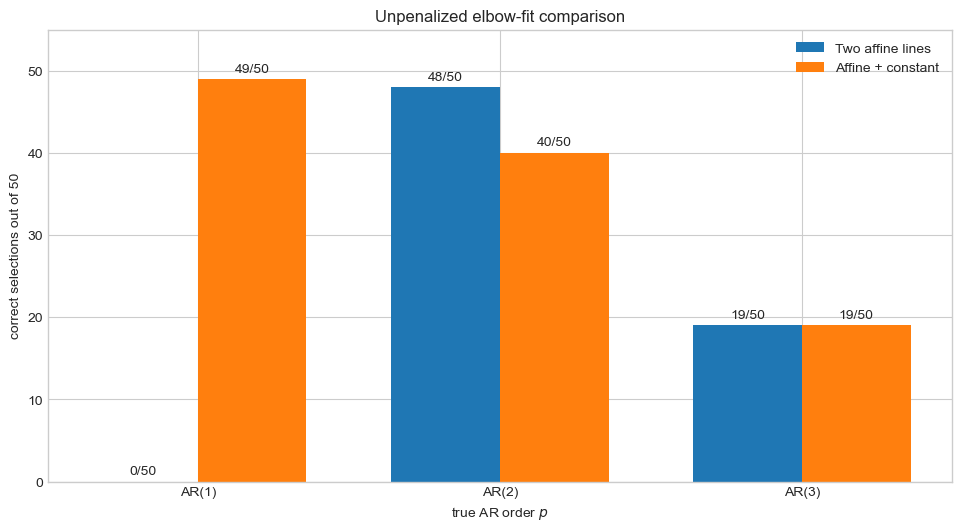

Correct selections out of 50
true_order          1   2   3
method                       
Two affine lines    0  48  19
Affine + constant  49  40  19


In [2]:
elbow_settings = [
    {"true_order": 1, "seed": 20260813},
    {"true_order": 2, "seed": 20260814},
    {"true_order": 3, "seed": 20260816},
]
elbow_rows = []
elbow_sample_size_T = 2_000
elbow_k_values = np.arange(1, 11)
for setting in elbow_settings:
    true_order = setting["true_order"]
    experiment_seed = setting["seed"]
    for replication in range(50):
        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication,
            sample_size=elbow_sample_size_T,
            burnin=1_000,
            half_width=1.0,
            rng=process_generator,
        )
        _, minimized_widths, _ = batched_geometric_width_curves(
            series_replication,
            elbow_k_values,
            seed=experiment_seed,
            replication=replication,
            starts=3,
            iterations=500,
            initial_step=0.2,
            geometric_decay=0.99,
        )
        selections = {
            "Two affine lines": l_method_selector(
                minimized_widths, weighted=True, common_breakpoint=False,
                affine_affine=True, squared_loss=True,
            ),
            "Affine + constant": l_method_selector(
                minimized_widths, weighted=True, common_breakpoint=True,
                affine_affine=False, squared_loss=True,
            ),
        }
        for method, selection in selections.items():
            elbow_rows.append({
                "true_order": true_order,
                "replication": replication + 1,
                "method": method,
                "plateau_onset": selection["plateau_onset"],
                "selected_order": selection["selected_order"],
                "fit_score": selection["score"],
                "correct_order": selection["selected_order"] == true_order,
            })
        if (replication + 1) % 10 == 0:                                                             ### REPORTING
            print(                                                                                  ### REPORTING
                f"Completed {replication + 1}/50 AR({true_order}) processes"                        ### REPORTING
            )                                                                                       ### REPORTING

elbow_results = pd.DataFrame(elbow_rows)
method_order = ["Two affine lines", "Affine + constant"]
elbow_accuracy = (
    elbow_results.groupby(["method", "true_order"])["correct_order"]
    .sum().unstack(fill_value=0).reindex(method_order)
)

fig, axis = plt.subplots(figsize=(9.5, 5.2), constrained_layout=True)                               ### PLOTTING
x_positions = np.arange(3)                                                                          ### PLOTTING
bar_width = 0.36                                                                                    ### PLOTTING
for method_index, method in enumerate(method_order):                                                ### PLOTTING
    counts = elbow_accuracy.loc[method, [1, 2, 3]].to_numpy()                                       ### PLOTTING
    offsets = x_positions + (method_index - 0.5) * bar_width                                        ### PLOTTING
    bars = axis.bar(offsets, counts, width=bar_width, label=method)                                 ### PLOTTING
    axis.bar_label(bars, labels=[f"{int(count)}/50" for count in counts], padding=3)                ### PLOTTING
axis.set(                                                                                           ### PLOTTING
    title="Unpenalized elbow-fit comparison",                                                       ### PLOTTING
    xlabel=r"true AR order $p$",                                                                    ### PLOTTING
    ylabel="correct selections out of 50",                                                          ### PLOTTING
    xticks=x_positions, xticklabels=["AR(1)", "AR(2)", "AR(3)"], ylim=(0, 55),                      ### PLOTTING
)                                                                                                   ### PLOTTING
axis.legend()                                                                                       ### PLOTTING
elbow_figure_path = (                                                                               ### PLOTTING
    ORDER_SELECTION_IMAGES_DIR / "cross_process"                                                    ### PLOTTING
    / "unpenalized_elbow_fits_p1_p2_p3_50_each_T2000.png"                                           ### PLOTTING
)                                                                                                   ### PLOTTING
fig.savefig(elbow_figure_path, dpi=200, bbox_inches="tight")                                        ### PLOTTING
plt.show()                                                                                          ### PLOTTING

print("Correct selections out of 50")                                                               ### REPORTING
print(elbow_accuracy.to_string())                                                                   ### REPORTING


**Interpretation.** This block is deliberately limited to the two unpenalized curve-fitting rules. The classical construction has a structural lower bound of $\widehat p\ge2$ because both disjoint affine segments need at least two observations. The modified affine-plus-constant construction removes that guardrail by sharing the candidate plateau-onset point between its two fits. Numerical results should be interpreted as a comparison of these two model shapes, without tuning an order penalty.


The former single-process geometry and optimizer-trajectory material is in the [temporary exploration notebook](ar_minimum_width_exploration_temp.ipynb). The single-process thesis figure examples are in [Figures 2.1–2.3](ar_thesis_figures_2_1_to_2_3.ipynb).